# Simulation 2 -- Monte Carlo study across all four GPDFlow-family models

One-factor Gumbel copula + Burr XII margins DGP, threshold exceedances at
`THRESHOLD`. Each of the four models (likelihood GPDFlow, MMD GPDFlow,
parametric mGPD, probit-copula NSF baseline) is fitted once on the full
exceedance set: cosine LR over 500 epochs, hard-stopped at its best-config
epoch (no CV / validation). Metrics are computed from `N_EVAL` draws per
fitted model, repeated for `N_SIM` replicates.  Ported from `Simulation_2S_best_config.ipynb`'s
single-fit exploration into a reusable Monte Carlo simulation study via
`cv_utils.run_simulation_study_2` / `summarize_simulation_study_2`.
Hyperparameters are the q = 0.96 winners of the NSF sweep
(`tune_sim2s_hparams.py` -> `Data_and_Model/sim2s_nsf/best_configs.json`).

In [1]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import cv_utils
importlib.reload(cv_utils)
from cv_utils import (
    simulate_2_factorcopula_burr,
    run_simulation_study_2,
    summarize_simulation_study_2,
    marginal_quantiles_true,
    prob_curve_true,
    prob_exactly_k_exceed,
    prob_joint_exceed,
    max_component_quantile,
)
import Common_Functions as cf

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

## Config

In [2]:
SMOKE = False  # set False for the full run

DIM = 20
N_EVAL = 20_000_000  # simulated rows per fitted model for the metrics

SIM_KWARGS = dict(n_samples=10000, dim=DIM, theta_max=7.0)

# Model hyperparameters: q = 0.96 winners of the NSF 5-fold-CV sweep
# (tune_sim2s_hparams.py -> Data_and_Model/sim2s_nsf/best_configs.json).
# Each model is fitted once on the full exceedance set: cosine LR over EPOCHS,
# hard-stopped at stop_at_epoch.
EPOCHS = 5 if SMOKE else 500                     # cosine-LR T_max
# stop_at_epoch = median per-fold best epoch in best_configs.json (q = 0.96)
STOP = dict(likelihood=146, mmd=174, parametric=450, baseline=222)
if SMOKE:
    STOP = {k: 5 for k in STOP}

LIK_KWARGS = dict(                               # best_configs['0.96']['lik']
    num_layers=2, latent_size_factor=2, penalty_lambda=1e4, marg_lambda=300,
    seed=1234, init_from_gpd=True,
    flow_type='nsf', flow_kw=dict(num_bins=7, num_blocks=1, tail_bound=5.0),
    epochs=EPOCHS, stop_at_epoch=STOP['likelihood'],
)
MMD_KWARGS = dict(                               # best_configs['0.96']['mmd']
    penalty_lambda=1e4, mmd_censor_c=0, mmd_censor_tau=0.2,
    mmd_indicator_alpha=3, mmd_indicator_rho=5,
    num_layers=4, latent_size_factor=2, seed=1234,
    flow_type='nsf', flow_kw=dict(num_bins=3, num_blocks=2, tail_bound=5.0),
    epochs=EPOCHS, stop_at_epoch=STOP['mmd'],
    # warmup_epochs=50, min_delta=1e-3, mmd_lambda=1, mmd_samples_per_face=128
    # are function defaults (cv_utils._SIM2_MMD_DEFAULTS)
)
PAR_KWARGS = dict(                               # best_configs['0.96']['par']
    generator='log_gamma', seed=1234,
    epochs=EPOCHS, stop_at_epoch=STOP['parametric'],
)
BL_KWARGS = dict(                                # best_configs['0.96']['bl']
    warmup=20, seed=0, num_layers=2, hidden_mult=2,
    flow_type='nsf', flow_kw=dict(num_bins=3, num_blocks=2, tail_bound=4.0),
    epochs=EPOCHS, stop_at_epoch=STOP['baseline'],
)

N_SIM = 2 if SMOKE else 50
THRESHOLD = 0.96
CHI_THRESHOLD_Q = 0.9999
MARG_THRESHOLD_Q = 0.9999
K_EXCEED = 5
JOINT_COMP_IDX = [0, 1, 2, 3, 4]  # Plot E: P(X_j > Q_j(q) for all j in JOINT_COMP_IDX)
Q_GRID_N = 80

N_BIG = 20_000 if SMOKE else 2_000_000

MODELS = [
    ('GPDFlow (Likelihood)', 'likelihood', 'darkgoldenrod'),
    ('GPDFlow (MMD)', 'mmd', 'firebrick'),
    ('Probit-transformed NSF', 'baseline', 'steelblue'),
    ('Parametric mGPD (Log-gamma)', 'parametric', 'seagreen'),
]
TRUTH_C = 'darkslategray'

## Truth / evaluation grid (run once)

This is the expensive one-off Monte Carlo cost: one `N_BIG`-row draw, used
for `Q_GRID`/`U_MATS` and for every truth (pairwise chi, marginal quantile,
prob-k, max-component). It is O(1) in `N_SIM` but non-trivial at full size
(2,000,000 rows) -- use `SMOKE=True` above for a fast first pass.

**All Monte Carlo drawing for evaluation happens here, in the notebook --
neither `run_simulation_study_2` nor `summarize_simulation_study_2` draws
anything internally.** If you change `THRESHOLD`, `Q_GRID_N`,
`MARG_THRESHOLD_Q`, `CHI_THRESHOLD_Q`, `K_EXCEED`, or `SIM_KWARGS`, you must
re-run this cell (and the study cell after it) -- a stale `Q_GRID`/`U_MATS`
built under different settings would silently misscore `prob_k_hat` /
`max_comp_hat`.

In [3]:
Q_GRID = 1.0 - np.geomspace(1.0 - THRESHOLD, 1e-4, Q_GRID_N)

# Single large draw, reused for U_MATS construction and for every truth:
# marginal quantile / prob-k / max-component and the pairwise chi (rank-based,
# so it depends on the copula only).
X_big = simulate_2_factorcopula_burr(n_samples=N_BIG, seed=20260908, dim=DIM,
                                     theta_max=SIM_KWARGS['theta_max'])
U_MATS = [np.quantile(X_big, q, axis=0) for q in Q_GRID]
marg_q_true = marginal_quantiles_true(X_big, MARG_THRESHOLD_Q)
fn_k = lambda X, u: prob_exactly_k_exceed(X, u, K_EXCEED)
prob_k_true = prob_curve_true(X_big, U_MATS, fn_k)
fn_joint = lambda X, u: prob_joint_exceed(X, u, JOINT_COMP_IDX)
prob_joint_true = prob_curve_true(X_big, U_MATS, fn_joint)
max_comp_true = max_component_quantile(X_big, Q_GRID, p_cluster=1.0)
chi_true_mat = cf.pairwise_chi_from_data(X_big, p=CHI_THRESHOLD_Q)
chi_true_pairs = chi_true_mat[np.triu_indices(DIM, k=1)]
del X_big

print('Q_GRID', Q_GRID.shape, ' U_MATS', len(U_MATS), ' marg_q_true', marg_q_true.shape)
print('prob_k_true', prob_k_true.shape, ' max_comp_true', max_comp_true.shape)
print('chi_true_pairs', chi_true_pairs.shape, ' prob_joint_true', prob_joint_true.shape)

Q_GRID (80,)  U_MATS 80  marg_q_true (20,)
prob_k_true (80,)  max_comp_true (80,)
chi_true_pairs (190,)  prob_joint_true (80,)


## Run the simulation study

In [4]:
N_SIM

50

In [ ]:
results = run_simulation_study_2(
    n_sim=N_SIM, device=device, base_seed=42, threshold=THRESHOLD,
    sim_kwargs=SIM_KWARGS,
    lik_kwargs=LIK_KWARGS, mmd_kwargs=MMD_KWARGS,
    par_kwargs=PAR_KWARGS, bl_kwargs=BL_KWARGS,
    n_eval=N_EVAL,
    chi_threshold_q=CHI_THRESHOLD_Q, marg_threshold_q=MARG_THRESHOLD_Q,
    k_exceed=K_EXCEED, Q_GRID=Q_GRID, U_MATS=U_MATS,
    joint_comp_idx=JOINT_COMP_IDX,
    verbose=not SMOKE,
)


===== simulation replicate 1/50 (DGP seed 42) =====


[replicate 1] p_cluster=0.1256  p_sim_chi=0.9992  p_sim_marg=0.9992
  scipy margin init  gamma~[0.343 0.379 0.174 0.17  0.06  0.398 0.352 0.292 0.198 0.075 0.388 0.348
 0.202 0.237 0.039 0.316 0.405 0.175 0.227 0.065]
  scipy margin init  sigma~[1.14  0.94  0.48  0.564 0.175 1.048 1.011 0.384 0.568 0.174 0.969 1.005
 0.439 0.532 0.186 1.126 0.952 0.461 0.534 0.176]
  epoch    1/500 | train=204.2842
  epoch   25/500 | train=190.2196
  epoch   50/500 | train=191.0204
  epoch   75/500 | train=190.2797
  epoch  100/500 | train=187.8797
  epoch  125/500 | train=191.5628
  stopping at fixed epoch 146 (stop_at_epoch).
[mmd] full fit (train 1256/1256)
  epoch    1/500 | train=0.2030
  epoch   25/500 | train=0.0102
  epoch   50/500 | train=0.0093
  epoch   75/500 | train=0.0086
  epoch  100/500 | train=0.0086
  epoch  125/500 | train=0.0056
  epoch  150/500 | train=0.0032
  stopping at fixed epoch 174 (stop_at_epoch).
[parametric:log_gamma] full fit (train 1256)
  [log_gamma ] ep   0  batch los

In [ ]:
1

1

In [9]:
# full fit
summary_df, summary = summarize_simulation_study_2(
    results, chi_true_pairs=chi_true_pairs, marg_q_true=marg_q_true,
    prob_k_true=prob_k_true, max_comp_true=max_comp_true,
)
summary_df

,rmse_chi,tde_chi,rmse_log_marg_q,ljpe_probk,rmsle_probk,rmse_log_maxcomp
likelihood,0.048200,0.035319,0.123273,0.258488,0.306336,0.069460
mmd,0.035449,0.029297,0.130449,0.214316,0.256890,0.073528
parametric,0.082202,0.047659,0.363536,0.604327,0.682362,0.647716
baseline,0.225038,0.214704,0.191422,0.333107,0.418610,0.095528


In [ ]:
# mmd_lambda= 1
summary_df, summary = summarize_simulation_study_2(
    results, chi_true_pairs=chi_true_pairs, marg_q_true=marg_q_true,
    prob_k_true=prob_k_true, max_comp_true=max_comp_true,
)
summary_df

,rmse_chi,tde_chi,rmse_log_marg_q,ljpe_probk,rmsle_probk,rmse_log_maxcomp
likelihood,0.049897,0.035141,0.091431,0.232204,0.274274,0.046190
mmd,0.038629,0.032363,0.094987,0.170954,0.205330,0.058504
parametric,0.081015,0.045089,0.388480,0.570226,0.649918,0.715833
baseline,0.206734,0.198521,0.130952,0.356611,0.403386,0.090665


In [ ]:
19*4

76

In [ ]:
# mmd_lambda= 15
summary_df, summary = summarize_simulation_study_2(
    results, chi_true_pairs=chi_true_pairs, marg_q_true=marg_q_true,
    prob_k_true=prob_k_true, max_comp_true=max_comp_true,
)
summary_df

,rmse_chi,tde_chi,rmse_log_marg_q,ljpe_probk,rmsle_probk,rmse_log_maxcomp
likelihood,0.049897,0.035141,0.091431,0.232204,0.274274,0.046190
mmd,0.038629,0.032363,0.094987,0.170954,0.205330,0.058504
parametric,0.081015,0.045089,0.388480,0.570226,0.649918,0.715833
baseline,0.206734,0.198521,0.130952,0.356611,0.403386,0.090665


## Plot A -- pairwise chi

Points = mean over the `N_SIM` replicates; vertical bars = pointwise 2.5%-97.5%
quantiles across replicates (95% band for a single fit).

In [10]:
dir_out = "/home/pgrad2/2448355h/My_PhD_Project/GPDFlow/Data_and_Model/"

In [ ]:
MODELS[0]

('GPDFlow (Likelihood)', 'likelihood', 'darkgoldenrod')

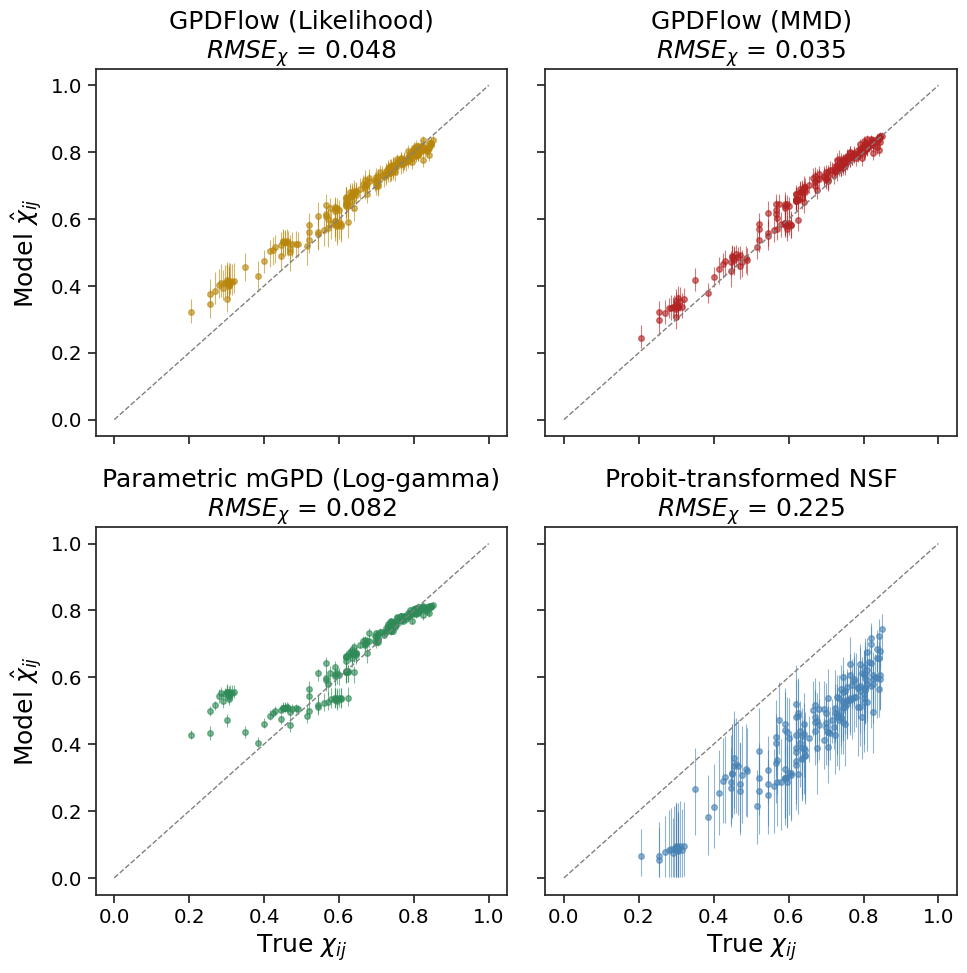

In [11]:
import seaborn as sns

BAND_Q = (0.025, 0.975)  # 95% band for a single fit: across-replicate quantiles
sns.set(style="ticks", font_scale=1.3)
# Plot A style, reused by Plots B-E
FIGSIZE_A = (10, 10)
TITLE_FS = LABEL_FS = 18
TICK_FS = plt.rcParams['xtick.labelsize']
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_A, sharex=True, sharey=True)
# Plot-A-only panel order: parametric mGPD bottom-left, probit NSF bottom-right
MODELS_A = [MODELS[0], MODELS[1], MODELS[3], MODELS[2]]
for ax, (label, key, color) in zip(axes.ravel(), MODELS_A):
    hat = results['per_model'][key]['chi_hat_pairs']
    mean_hat = hat.mean(axis=0)
    lo, hi = np.quantile(hat, BAND_Q, axis=0)
    # vlines rather than errorbar: with skewed replicates the mean can fall
    # outside [lo, hi], which errorbar's non-negative yerr cannot express
    ax.vlines(chi_true_pairs, lo, hi, color=color, alpha=0.6, linewidth=0.8)
    ax.plot(chi_true_pairs, mean_hat, 'o', color=color, alpha=0.6, markersize=4)
    ax.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
    # RMSE_chi per replicate vs truth, averaged over replicates
    rmse = np.mean([cf.rmse_chi(h, chi_true_pairs) for h in hat])
    ax.set_title(f"{label}\n"
                 rf"$RMSE_\chi$ = {rmse:.3f}",
                 color='black', fontsize=TITLE_FS)
    ax.tick_params(axis='both', labelcolor='black', labelsize=TICK_FS)
for i, ax in enumerate(axes.ravel()):
    if i // 2 == 1:
        ax.set_xlabel(r'True $\chi_{ij}$', color='black', fontsize=LABEL_FS)
    if i % 2 == 0:
        ax.set_ylabel(r'Model $\hat{\chi}_{ij}$', color='black', fontsize=LABEL_FS)
# fig.suptitle(f'Pairwise chi at threshold_q={CHI_THRESHOLD_Q} ({hat.shape[0]} replicates)',
#              fontsize=18)
fig.tight_layout()
# panel positions (figure coords) after layout: B-E pin their axes to these
PANEL_POS_A = [ax.get_position() for ax in axes.ravel()]
fig.savefig(dir_out + 'Plots/Scenario2_pairwise_chi.pdf', bbox_inches='tight')
plt.show()

## Plot helpers for B-E

Each B-E plot shows four models with a 95% across-replicate band. On one axis
the bands overlap, so C/D/E use a 2x2 grid instead (panel order as Plot A).
Each panel shows one model's mean and band; the other three models' means are
drawn as thin grey lines so the models can still be compared. C and E are
plotted as $\log(\hat p / p)$ rather than raw probabilities:
- a replicate with 0 hits among its `N_EVAL` draws is floored at the Monte
  Carlo resolution $0.5\,p_{cluster}/N_{EVAL}$, not at `1e-12`;
- all of `Q_GRID` is shown; at the top of the grid few of the `N_EVAL` draws
  exceed, so the bands widen there (only $q$ with a zero true probability are dropped).

All four panels share one y-axis, as in Plot A.


In [19]:
from matplotlib.transforms import Bbox

# results must have been built on the current THRESHOLD grid
assert np.isclose(results['Q_GRID'][0], THRESHOLD), results['Q_GRID'][0]

BAND_Q = (0.025, 0.975)  # 95% band for a single fit: across-replicate quantiles
MODELS_A = [MODELS[0], MODELS[1], MODELS[3], MODELS[2]]  # panel order as Plot A
GHOST_C = '0.6'
Q_TICKS = [0.96, 0.99, 0.999, 0.9999]  # logit-axis major ticks
# saved C/D/E PDFs span a fixed width left of the panels, so their size does
# not depend on the y tick label width (bbox_inches='tight' would make a plot
# with wider labels, e.g. '-0.25' vs '-3', a wider PDF that LaTeX shrinks more)
SAVE_LEFT_IN = 1.3


def prob_floor():
    """Per-replicate MC resolution of a prob estimate, shape (n_sim, 1):
    estimates are p_cluster * (fraction of N_EVAL draws), so 0 hits -> 0."""
    return (0.5 * results['p_cluster'] / N_EVAL)[:, None]


def log_ratio_prob(hat, truth):
    """log(p_hat / p_true), with p_hat floored at the MC resolution."""
    return np.log(np.maximum(hat, prob_floor()) / truth)


def report_floor(stat_key, ok):
    """Fraction of (replicate, q) cells with 0 simulated hits, per model."""
    for label, key, _ in MODELS:
        hat = results['per_model'][key][stat_key][:, ok]
        print(f'{label:30s} zero-hit fraction = {np.mean(hat < prob_floor()):.3f}')


def _layout_like_plot_a(fig, axes, ylabel, pad_pt=4):
    """Pin the 2x2 axes to Plot A's panel positions (no tight_layout, which
    would resize the panels around the long y label).  One y label is
    centred on the left column, pad_pt from its tick labels (the default
    labelpad, as in Plot A)."""
    for ax, pos in zip(axes.ravel(), PANEL_POS_A):
        ax.set_position(pos)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    left = min(ax.yaxis.get_tightbbox(r).x0 for ax in axes[:, 0])
    y_mid = (axes[1, 0].get_position().y0 + axes[0, 0].get_position().y1) / 2
    fig.supylabel(ylabel, color='black', fontsize=LABEL_FS, ha='right',
                  x=(left - pad_pt / 72 * fig.dpi) / fig.bbox.width, y=y_mid)


def _fixed_save_bbox(fig, pad_in=0.1):
    """Tight bbox (inches) except the left edge, which is put SAVE_LEFT_IN
    left of the panels.  Right/top/bottom are the same across C/D/E (same
    titles, x ticks and x label), so the saved PDFs all have the same size."""
    r = fig.canvas.get_renderer()
    tight = fig.get_tightbbox(r)
    x0 = PANEL_POS_A[0].x0 * fig.get_figwidth() - SAVE_LEFT_IN
    if tight.x0 < x0:
        print(f'warning: y labels need {x0 - tight.x0 + SAVE_LEFT_IN:.2f} in; '
              'raise SAVE_LEFT_IN or they are clipped')
    return Bbox.from_extents(x0, tight.y0 - pad_in, tight.x1 + pad_in,
                             tight.y1 + pad_in)


def plot_band_panels(curves, x, ylabel, fname=None,
                     xlabel='q', xscale='logit', pad=0.08):
    """2x2 small multiples of per-replicate curves on the plotted scale.

    curves: {model key: (n_sim, len(x)) array}.  Panel = that model's mean +
    95% band; other models' means as grey ghosts; 0 reference line.  All
    panels share one y-axis, as in Plot A.
    """
    stats = {}
    for _, key, _ in MODELS_A:
        c = curves[key]
        lo, hi = np.quantile(c, BAND_Q, axis=0)
        # RMSE over x per replicate, averaged over replicates
        rmse = np.mean(np.sqrt(np.mean(c ** 2, axis=1)))
        stats[key] = (c.mean(axis=0), lo, hi, rmse)
    ymin = min(0.0, min(s[1].min() for s in stats.values()))
    ymax = max(0.0, max(s[2].max() for s in stats.values()))
    span = ymax - ymin

    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_A, sharex=True, sharey=True)
    for ax, (label, key, color) in zip(axes.ravel(), MODELS_A):
        for _, k2, _ in MODELS_A:
            if k2 != key:
                ax.plot(x, stats[k2][0], color=GHOST_C, linewidth=1, zorder=1)
        mean, lo, hi, rmse = stats[key]
        ax.fill_between(x, lo, hi, color=color, alpha=0.3, linewidth=0, zorder=2)
        ax.plot(x, mean, color=color, linewidth=2.2, zorder=3)
        ax.axhline(0, color='gray', linestyle='--', linewidth=1, zorder=0)
        ax.set_xscale(xscale)
        if xscale == 'logit':
            ax.set_xticks(Q_TICKS, [str(t) for t in Q_TICKS])
            ax.set_xlim(x[0], x[-1])  # span exactly [THRESHOLD, 0.9999]
            ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_title(f'{label}\nRMSE = {rmse:.3f}', color='black', fontsize=TITLE_FS)
        ax.tick_params(axis='both', which='both', labelcolor='black',
                       labelsize=TICK_FS)
    axes[0, 0].set_ylim(ymin - pad * span, ymax + pad * span)
    for ax in axes[1]:
        ax.set_xlabel(xlabel, color='black', fontsize=LABEL_FS)
    _layout_like_plot_a(fig, axes, ylabel)
    if fname is not None:
        fig.savefig(dir_out + 'Plots/' + fname, bbox_inches=_fixed_save_bbox(fig))
    plt.show()


## Plot B -- log ratio of the marginal quantile at `MARG_THRESHOLD_Q`

Points = mean of $\log(\hat Q_j/Q_j)$ over the `N_SIM` replicates (0 = unbiased;
over- and under-estimation by the same factor are symmetric); vertical bars =
pointwise 2.5%-97.5% quantiles across replicates (95% band for a single fit).
Models are offset horizontally within each margin so their bars do not overlap.


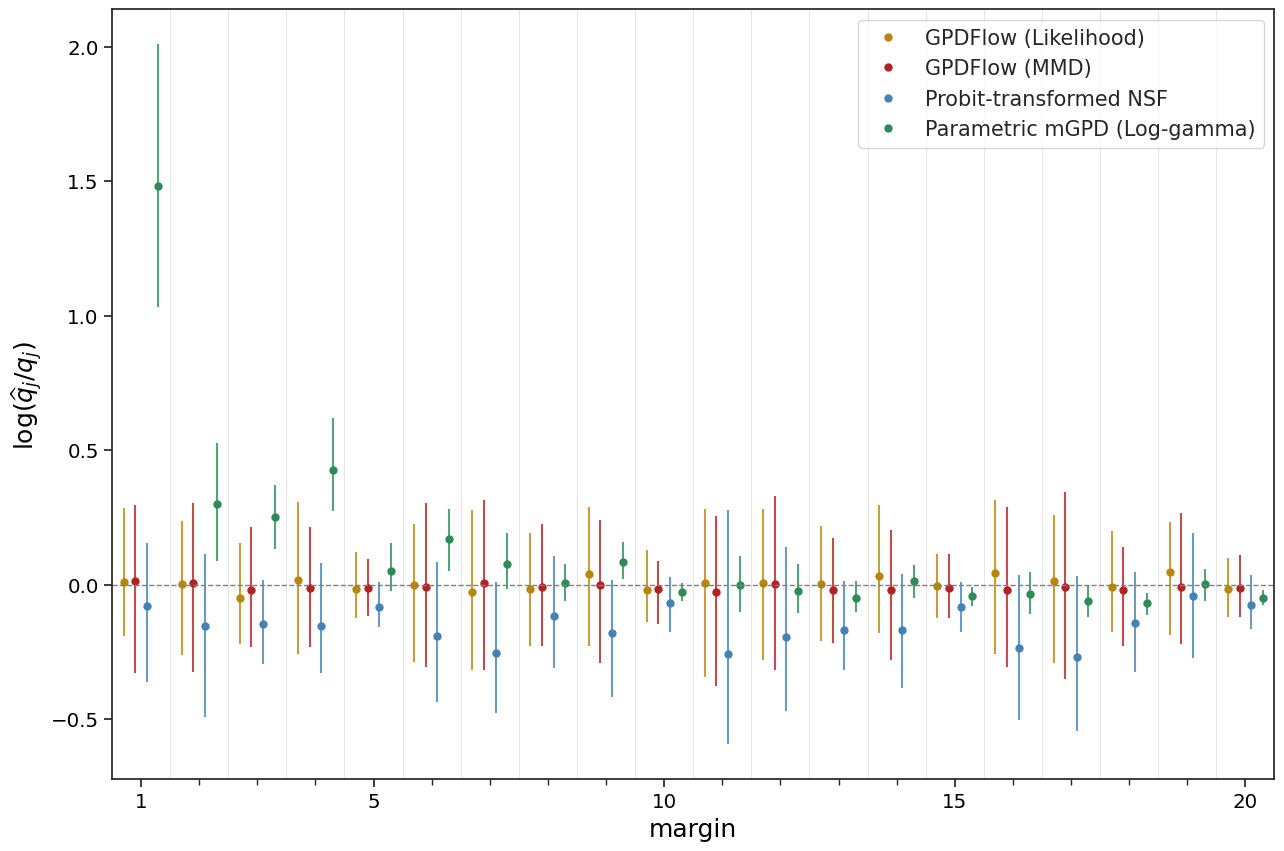

In [13]:
dims_ax = np.arange(1, DIM + 1)
offsets = np.linspace(-0.3, 0.3, len(MODELS))  # dodge models within a margin
# Plot A's figure height, 1.25x its width
fig, ax = plt.subplots(figsize=(1.5 * FIGSIZE_A[0], FIGSIZE_A[1]))
for (label, key, color), off in zip(MODELS, offsets):
    hat = results['per_model'][key]['marg_q_hat']
    # log ratio: over- and under-estimation by the same factor are symmetric,
    # and it is the same log scale as the rmse_log_marg_q summary metric
    log_ratio = np.log(hat / marg_q_true)
    log_mean = log_ratio.mean(axis=0)
    lo, hi = np.quantile(log_ratio, BAND_Q, axis=0)
    # vlines rather than errorbar: the mean can fall outside [lo, hi]
    ax.vlines(dims_ax + off, lo, hi, color=color, alpha=0.8, linewidth=1.5)
    ax.plot(dims_ax + off, log_mean, 'o', color=color, label=label, markersize=5)
for sep in dims_ax[:-1] + 0.5:
    ax.axvline(sep, color='0.9', linewidth=0.8, zorder=0)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(0.5, DIM + 0.5)
ax.set_xlabel('margin', color='black', fontsize=LABEL_FS)
ax.set_ylabel(r'$\log(\widehat q_j / q_j)$',
              color='black', fontsize=LABEL_FS)
# 20 tick labels do not fit a Plot-A-sized panel: label every 5th margin
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_xticks(dims_ax, minor=True)
ax.tick_params(axis='both', which='both', labelcolor='black', labelsize=TICK_FS)
ax.legend(fontsize=15, loc='upper right')
fig.savefig(dir_out + 'Plots/Scenario2_marginal_quantile.pdf', bbox_inches='tight')
plt.show()


## Plot C -- `P(exactly K_EXCEED exceed)` vs `Q_GRID`

Log ratio $\log(\hat p/p)$ in a 2x2 grid (see the plot helpers above). Solid
line = mean over the `N_SIM` replicates; shaded band = pointwise 2.5%-97.5%
quantiles across replicates (95% band for a single fit). The zero-hit fractions printed below show how much
of a model's under-estimation comes from the Monte Carlo floor. The next cell
shows the same quantity as a raw probability.


GPDFlow (Likelihood)           zero-hit fraction = 0.000
GPDFlow (MMD)                  zero-hit fraction = 0.000
Probit-transformed NSF         zero-hit fraction = 0.011
Parametric mGPD (Log-gamma)    zero-hit fraction = 0.000


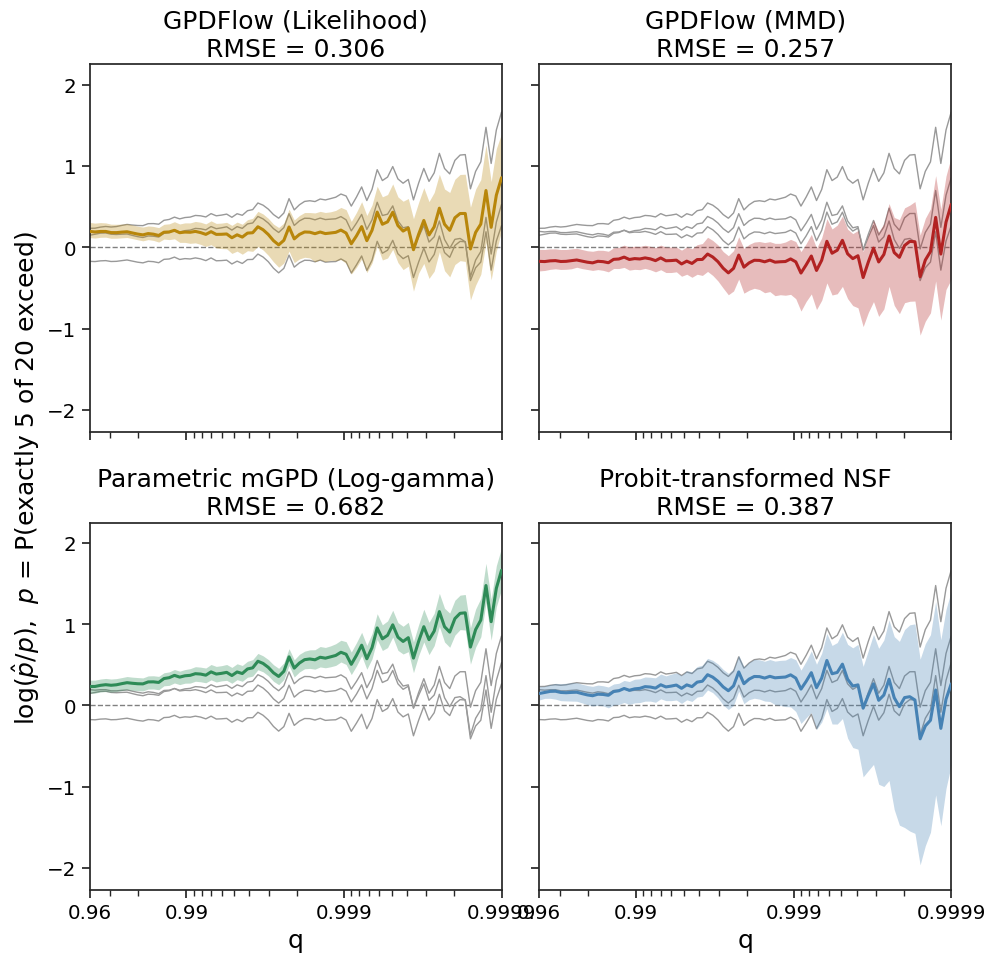

In [20]:
ok = prob_k_true > 0  # log ratio undefined where the truth is 0
report_floor('prob_k_hat', ok)
curves = {key: log_ratio_prob(results['per_model'][key]['prob_k_hat'][:, ok], prob_k_true[ok])
          for _, key, _ in MODELS}
plot_band_panels(curves, Q_GRID[ok],
                 rf'$\log(\hat p / p)$,  $p$ = P(exactly {K_EXCEED} of {DIM} exceed)',
                 fname='Scenario2_exactly_k_exceed_prob.pdf')


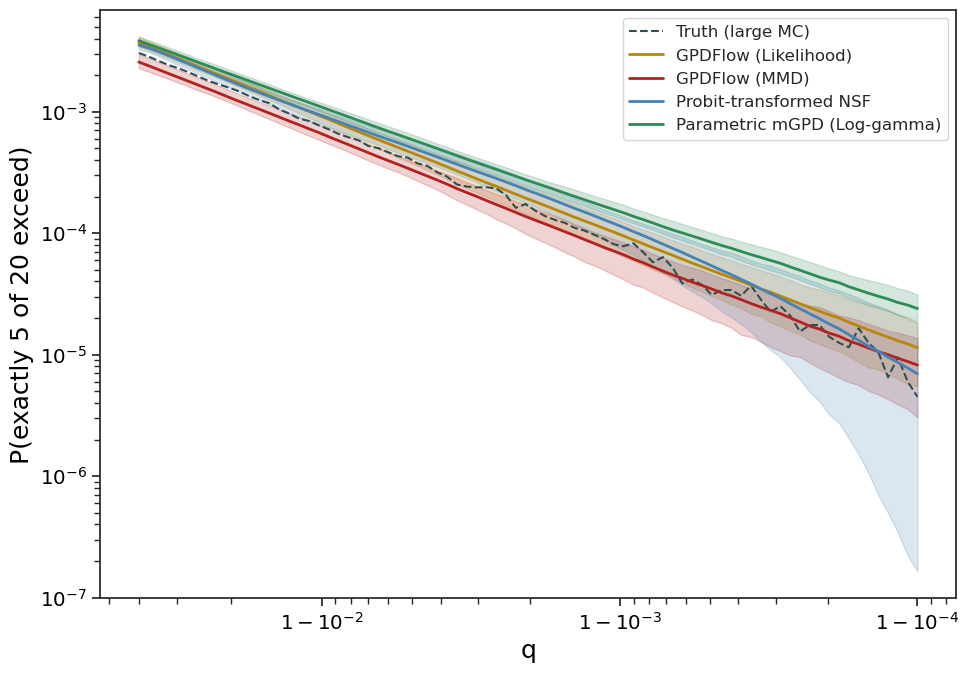

In [21]:
# Absolute-scale version of Plot C (not saved)
BAND_Q = (0.025, 0.975)  # 95% band for a single fit: across-replicate quantiles
fig, ax = plt.subplots(figsize=(10, 7))
ok = prob_k_true > 0
ax.plot(Q_GRID[ok], prob_k_true[ok], '--', color=TRUTH_C, label='Truth (large MC)')
for label, key, color in MODELS:
    hat = results['per_model'][key]['prob_k_hat']
    mean_hat = hat.mean(axis=0)
    lo, hi = np.quantile(hat, BAND_Q, axis=0)
    ax.plot(Q_GRID[ok], np.maximum(mean_hat[ok], 1e-12), color=color, linewidth=2, label=label)
    ax.fill_between(Q_GRID[ok], np.maximum(lo[ok], 1e-12), np.maximum(hi[ok], 1e-12),
                    color=color, alpha=0.2)
ax.set_yscale('log')
ax.set_xscale('logit')
ax.set_xlabel('q', color='black', fontsize=18)
ax.set_ylabel(f'P(exactly {K_EXCEED} of {DIM} exceed)', color='black', fontsize=18)
# ax.set_title(f'mean over {hat.shape[0]} replicates; band = 2.5-97.5% across replicates',
#              color='black', fontsize=18)
ax.tick_params(axis='both', which='both', labelcolor='black')
ax.legend(fontsize=12)
fig.tight_layout()
plt.show()

## Plot D -- log ratio of the componentwise-maximum quantile vs `Q_GRID`

Mean of $\log(\hat Q_M(q)/Q_M(q))$ over the `N_SIM` replicates (0 = unbiased)
in a 2x2 grid (see the plot helpers above); shaded band = pointwise 2.5%-97.5%
quantiles across replicates (95% band for a single fit). All panels share one
y-axis. The second cell shows the quantile $Q_M(q)$ itself on a log scale.


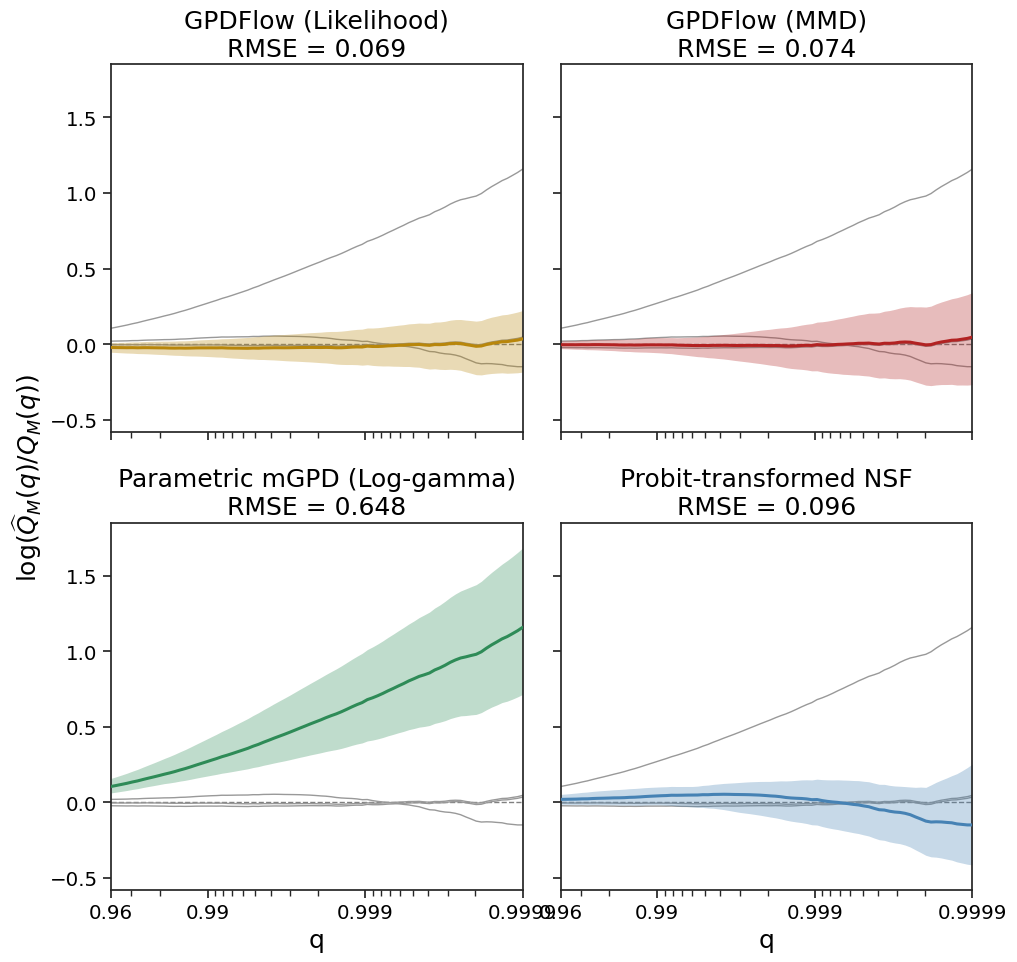

In [22]:
curves = {key: np.log(results['per_model'][key]['max_comp_hat'] / max_comp_true)
          for _, key, _ in MODELS}
plot_band_panels(curves, Q_GRID, r'$\log(\widehat Q_M(q) / Q_M(q))$',
                 fname='Scenario2_max_quantile.pdf')


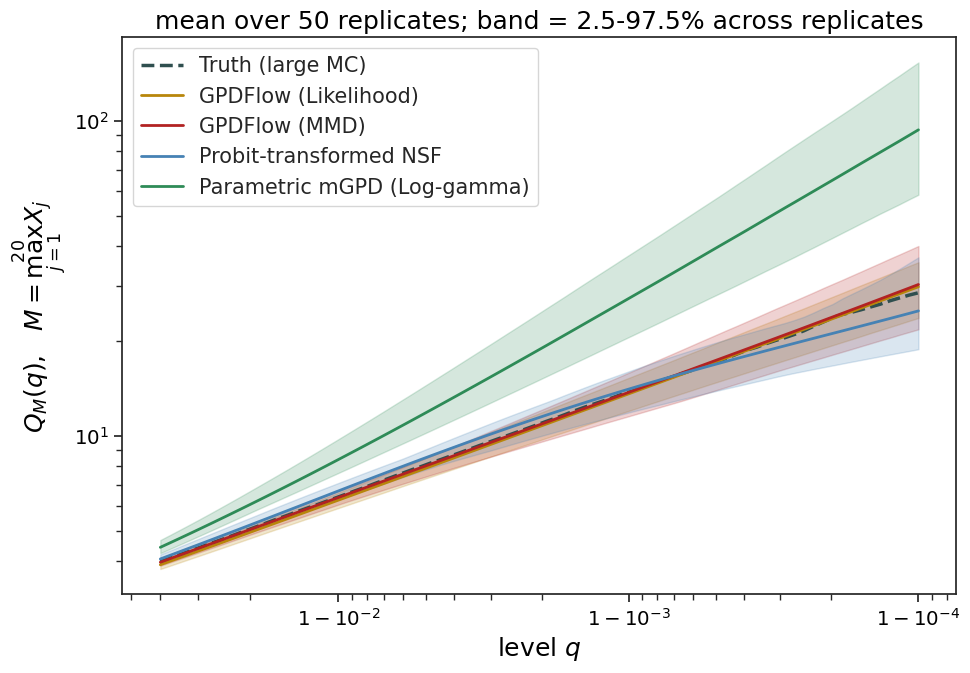

In [23]:
BAND_Q = (0.025, 0.975)  # 95% band for a single fit: across-replicate quantiles
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(Q_GRID, max_comp_true, '--', color=TRUTH_C, lw=2.5, label='Truth (large MC)')
for label, key, color in MODELS:
    hat = results['per_model'][key]['max_comp_hat']
    mean_hat = hat.mean(axis=0)
    lo, hi = np.quantile(hat, BAND_Q, axis=0)
    ax.plot(Q_GRID, mean_hat, color=color, linewidth=2, label=label)
    ax.fill_between(Q_GRID, lo, hi, color=color, alpha=0.2)
ax.set_xscale('logit')
ax.set_yscale('log')
ax.set_xlabel(r'level $q$', color='black', fontsize=18)
ax.set_ylabel(r'$Q_M(q)$,   $M = \max_{j=1}^{%d} X_j$' % DIM, color='black', fontsize=18)
ax.set_title(f'mean over {hat.shape[0]} replicates; band = 2.5-97.5% across replicates',
             color='black', fontsize=18)
ax.tick_params(axis='both', which='both', labelcolor='black')
ax.legend(fontsize=15)
fig.tight_layout()
plt.show()

## Plot E -- `P(X_j > Q_j(q), j in JOINT_COMP_IDX)` vs `Q_GRID`

Joint exceedance of the first 5 components (`JOINT_COMP_IDX = [0, 1, 2, 3, 4]`),
drawn the same way as Plot C: $\log(\hat p/p)$ in a 2x2 grid. The next cell shows the same
quantity as a raw probability.


GPDFlow (Likelihood)           zero-hit fraction = 0.002
GPDFlow (MMD)                  zero-hit fraction = 0.004
Probit-transformed NSF         zero-hit fraction = 0.179
Parametric mGPD (Log-gamma)    zero-hit fraction = 0.000


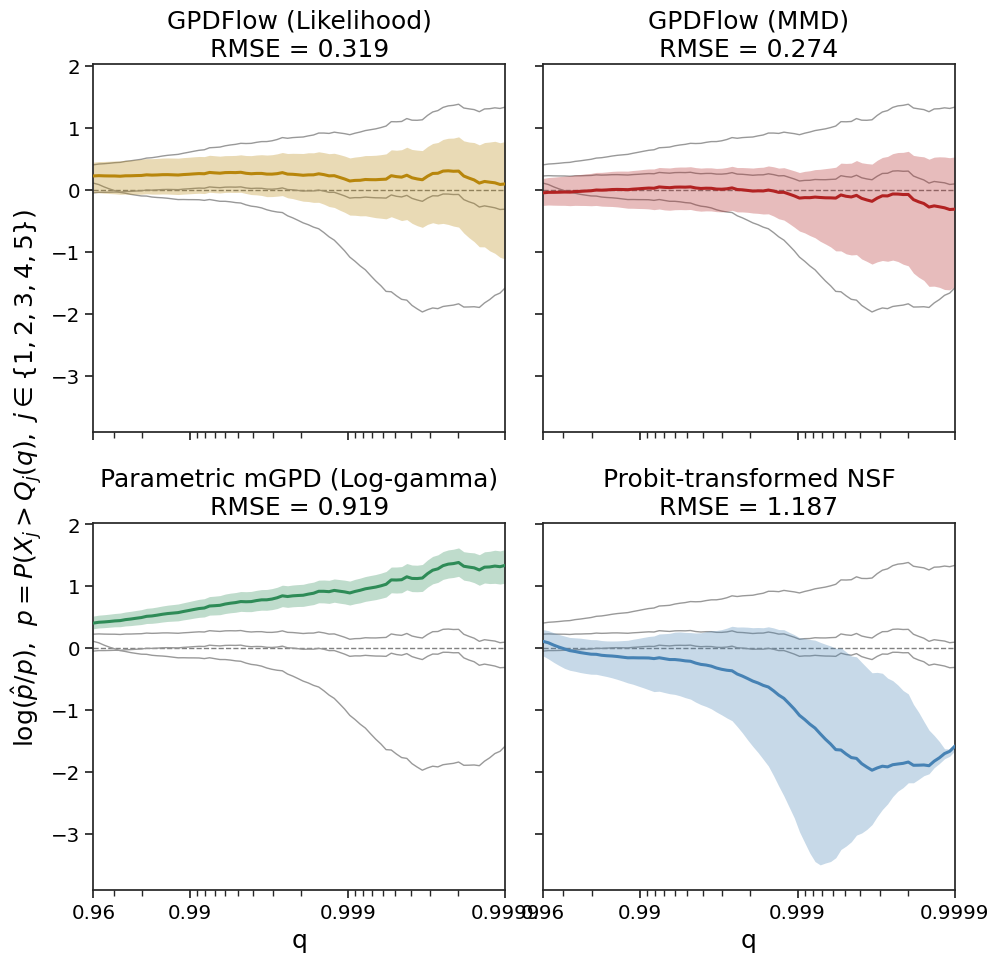

In [24]:
comp_str = ','.join(str(j + 1) for j in JOINT_COMP_IDX)  # 1-based for the label
ok = prob_joint_true > 0  # log ratio undefined where the truth is 0
report_floor('prob_joint_hat', ok)
curves = {key: log_ratio_prob(results['per_model'][key]['prob_joint_hat'][:, ok],
                              prob_joint_true[ok])
          for _, key, _ in MODELS}
plot_band_panels(curves, Q_GRID[ok],
                 rf'$\log(\hat p / p)$,  $p = P(X_j > Q_j(q),\ j \in \{{{comp_str}\}})$',
                 fname='Scenario2_joint_exceed_prob.pdf')


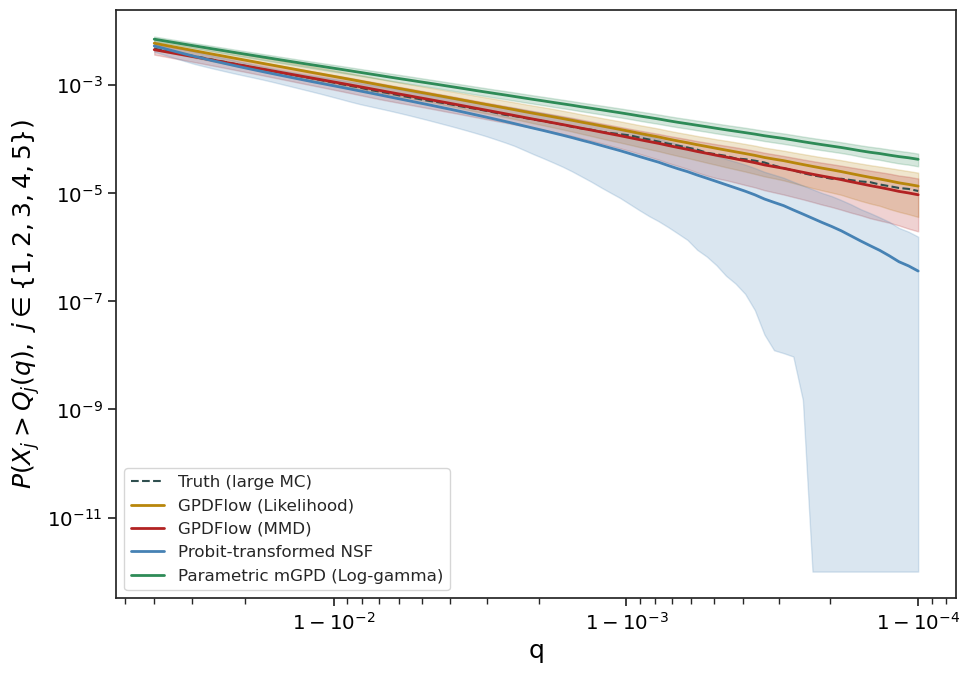

In [25]:
# Absolute-scale version of Plot E (not saved)
BAND_Q = (0.025, 0.975)  # 95% band for a single fit: across-replicate quantiles
comp_str = ','.join(str(j + 1) for j in JOINT_COMP_IDX)  # 1-based for the label
fig, ax = plt.subplots(figsize=(10, 7))
ok = prob_joint_true > 0
ax.plot(Q_GRID[ok], prob_joint_true[ok], '--', color=TRUTH_C, label='Truth (large MC)')
for label, key, color in MODELS:
    hat = results['per_model'][key]['prob_joint_hat']
    mean_hat = hat.mean(axis=0)
    lo, hi = np.quantile(hat, BAND_Q, axis=0)
    ax.plot(Q_GRID[ok], np.maximum(mean_hat[ok], 1e-12), color=color, linewidth=2, label=label)
    ax.fill_between(Q_GRID[ok], np.maximum(lo[ok], 1e-12), np.maximum(hi[ok], 1e-12),
                    color=color, alpha=0.2)
ax.set_yscale('log')
ax.set_xscale('logit')
ax.set_xlabel('q', color='black', fontsize=18)
ax.set_ylabel(rf'$P(X_j > Q_j(q),\ j \in \{{{comp_str}\}})$', color='black', fontsize=18)
# ax.set_title(f'mean over {hat.shape[0]} replicates; band = 2.5-97.5% across replicates',
#              color='black', fontsize=18)
ax.tick_params(axis='both', which='both', labelcolor='black')
ax.legend(fontsize=12)
fig.tight_layout()
plt.show()

## Summary score comparison

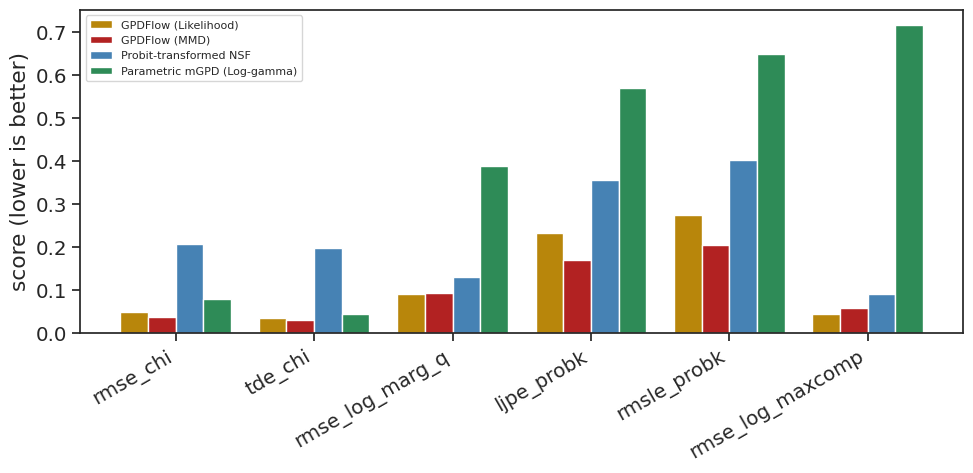

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
score_cols = summary_df.columns.tolist()
x = np.arange(len(score_cols))
width = 0.2
for i, (label, key, color) in enumerate(MODELS):
    ax.bar(x + (i - 1.5) * width, summary_df.loc[key, score_cols], width,
          label=label, color=color)
ax.set_xticks(x)
ax.set_xticklabels(score_cols, rotation=30, ha='right')
ax.set_ylabel('score (lower is better)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()